This notebook reproduces the Methods section *PPI clustering* and the Results section
*Pace-state clustering*: Supplementary Table S3 (clustering-method comparison), Figure 4,
Supplementary Figure S1 (boundary bootstrap) and Table 2 (pace-state profile and
per-feature cut-points).

**Input**: `../data/ppi-features.h5`.
**Output**: key `pace_states` in the same file.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import BaseEstimator, ClusterMixin
from sklearn.cluster import KMeans
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
                             davies_bouldin_score, roc_curve, silhouette_score)
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import GroupShuffleSplit

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

DATA_DIR = "../data"
FIG_DIR = "../figures"
PPI_H5 = os.path.join(DATA_DIR, "ppi-features.h5")
os.makedirs(FIG_DIR, exist_ok=True)

ppi = pd.read_hdf(PPI_H5, "ppi")
ITEMS = list(pd.read_hdf(PPI_H5, "horst_weights").index)
X = ppi[["PPI"]].to_numpy()
print(f"{len(ppi):,} possessions")

39,995 possessions


## 1 · Clustering-method comparison (Supplementary Table S3)

K-means, K-medians and a Gaussian mixture model (GMM) are fitted to the one-dimensional PPI for
K = 2–8 and the number of states is chosen by the silhouette score (the GMM BIC is reported for
information). At the selected K the three methods are compared in 30 repeated 80/20 holdouts
grouped by match (held-out silhouette, Calinski–Harabasz, Davies–Bouldin, label stability as ARI
against the full-sample solution). Eligible solutions need a mean ARI ≥ 0.90, a smallest cluster
≥ 5 % and exactly K − 1 boundaries on the PPI axis (contiguous, ordered states); among them the
lowest mean rank is selected.

In [2]:
class KMedians1D(BaseEstimator, ClusterMixin):
    """1-D K-medians (L1 objective) with multiple starts."""

    def __init__(self, n_clusters=3, max_iter=300, n_init=20, random_state=42):
        self.n_clusters, self.max_iter = n_clusters, max_iter
        self.n_init, self.random_state = n_init, random_state

    def fit(self, X, y=None):
        x = np.asarray(X, dtype=float).ravel()
        rng = np.random.default_rng(self.random_state)
        best_loss, best_centers, best_labels = np.inf, None, None
        for init in range(self.n_init):
            centers = (np.quantile(x, (np.arange(self.n_clusters) + 0.5) / self.n_clusters)
                       if init == 0 else np.sort(rng.choice(x, size=self.n_clusters, replace=False)))
            for _ in range(self.max_iter):
                dist = np.abs(x[:, None] - centers[None, :])
                labels = dist.argmin(axis=1)
                new = centers.copy()
                for k in range(self.n_clusters):
                    new[k] = (np.median(x[labels == k]) if np.any(labels == k)
                              else x[np.argmax(dist.min(axis=1))])
                new.sort()
                if np.allclose(centers, new, rtol=0, atol=1e-10):
                    break
                centers = new
            labels = np.abs(x[:, None] - centers[None, :]).argmin(axis=1)
            loss = np.abs(x - centers[labels]).sum()
            if loss < best_loss:
                best_loss, best_centers, best_labels = loss, centers.copy(), labels.copy()
        self.cluster_centers_ = best_centers.reshape(-1, 1)
        self.labels_, self.inertia_ = best_labels, best_loss
        return self

    def predict(self, X):
        x = np.asarray(X, dtype=float).ravel()
        return np.abs(x[:, None] - self.cluster_centers_.ravel()[None, :]).argmin(axis=1)


METHODS = ("kmeans", "gmm", "kmedians")
METHOD_LABELS = {"kmeans": "K-means", "gmm": "GMM", "kmedians": "K-medians"}
K_RANGE = range(2, 9)
RANDOM_STATE = 2025


def make_clusterer(method, k, seed=RANDOM_STATE):
    if method == "kmeans":
        return KMeans(n_clusters=k, random_state=seed, n_init=20)
    if method == "gmm":
        return GaussianMixture(n_components=k, covariance_type="full", random_state=seed,
                               n_init=10, reg_covar=1e-6)
    return KMedians1D(n_clusters=k, n_init=20, random_state=seed)


def decision_boundaries(model):
    """PPI values at which the predicted state changes (fine grid over P0.1–P99.9)."""
    lo, hi = np.quantile(X, [0.001, 0.999])
    grid = np.linspace(lo, hi, 30_001).reshape(-1, 1)
    cuts = np.flatnonzero(np.diff(model.predict(grid)) != 0)
    return ((grid[cuts, 0] + grid[cuts + 1, 0]) / 2).tolist()


def central_boundary(model, method):
    centres = np.sort((model.means_ if method == "gmm" else model.cluster_centers_).ravel())
    cuts = decision_boundaries(model)
    return np.nan if not cuts else min(cuts, key=lambda b: abs(b - centres.mean()))

In [3]:
# ── Stage 1: number of states (silhouette; GMM BIC for information) ──────────
sil = {m: [] for m in METHODS}
bic_gmm = []
full_models = {}
for k in K_RANGE:
    for m in METHODS:
        model = make_clusterer(m, k).fit(X)
        full_models[(m, k)] = model
        sil[m].append(silhouette_score(X, model.predict(X), sample_size=10_000,
                                       random_state=RANDOM_STATE))
        if m == "gmm":
            bic_gmm.append(model.bic(X))

k_sel = pd.DataFrame({METHOD_LABELS[m]: sil[m] for m in METHODS}, index=list(K_RANGE))
k_sel["GMM BIC"] = bic_gmm
k_sel.index.name = "K"
print(k_sel.round(4).to_string())
best_k = {m: k_sel.index[int(np.argmax(sil[m]))] for m in METHODS}
K_OPT = int(pd.Series(list(best_k.values())).mode().iloc[0])
print(f"\nSilhouette-optimal K: {best_k};  GMM BIC-optimal K = {k_sel['GMM BIC'].idxmin()}")
print(f"Selected K = {K_OPT}")

# ── Stage 2: method comparison at K_OPT, 30 match-grouped 80/20 holdouts ───────
rng_eval = np.random.default_rng(RANDOM_STATE)
eval_idx = rng_eval.choice(len(X), size=min(10_000, len(X)), replace=False)
X_eval = X[eval_idx]
reference = {m: full_models[(m, K_OPT)].predict(X_eval) for m in METHODS}

rows = []
splitter = GroupShuffleSplit(n_splits=30, test_size=0.20, random_state=RANDOM_STATE)
for split, (tr, te) in enumerate(splitter.split(X, groups=ppi["game_id"].to_numpy())):
    for m in METHODS:
        model = make_clusterer(m, K_OPT, seed=RANDOM_STATE + split + 1).fit(X[tr])
        lab = model.predict(X[te])
        _, counts = np.unique(lab, return_counts=True)
        rows.append(dict(
            method=m,
            silhouette=silhouette_score(X[te], lab, sample_size=min(3_000, len(te)),
                                        random_state=split),
            calinski_harabasz=calinski_harabasz_score(X[te], lab),
            davies_bouldin=davies_bouldin_score(X[te], lab),
            stability_ari=adjusted_rand_score(reference[m], model.predict(X_eval)),
            min_cluster_share=counts.min() / counts.sum(),
            boundary=central_boundary(model, m)))
validation = pd.DataFrame(rows)

table_s3 = validation.groupby("method").agg(
    silhouette_mean=("silhouette", "mean"), silhouette_sd=("silhouette", "std"),
    calinski_harabasz_mean=("calinski_harabasz", "mean"),
    davies_bouldin_mean=("davies_bouldin", "mean"),
    stability_ari_mean=("stability_ari", "mean"), stability_ari_sd=("stability_ari", "std"),
    min_cluster_share_mean=("min_cluster_share", "mean"),
    boundary_mean=("boundary", "mean"), boundary_sd=("boundary", "std"))
table_s3["mean_rank"] = pd.concat([table_s3["silhouette_mean"].rank(ascending=False),
                                   table_s3["calinski_harabasz_mean"].rank(ascending=False),
                                   table_s3["davies_bouldin_mean"].rank(ascending=True),
                                   table_s3["stability_ari_mean"].rank(ascending=False)],
                                  axis=1).mean(axis=1)
table_s3["boundary_count"] = [len(decision_boundaries(full_models[(m, K_OPT)]))
                              for m in table_s3.index]
table_s3["eligible"] = ((table_s3["stability_ari_mean"] >= 0.90)
                        & (table_s3["min_cluster_share_mean"] >= 0.05)
                        & (table_s3["boundary_count"] == K_OPT - 1))
pool = table_s3[table_s3["eligible"]] if table_s3["eligible"].any() else table_s3
CLUSTERING_METHOD = pool.sort_values(["mean_rank", "silhouette_mean"],
                                     ascending=[True, False]).index[0]

table_s3 = table_s3.rename(index=METHOD_LABELS).sort_values("mean_rank")
print("\n=== Table S3 ===")
print(table_s3.round(4).to_string())
print(f"\nSelected: {METHOD_LABELS[CLUSTERING_METHOD]}, K = {K_OPT}")
table_s3.round(4).to_csv(f"{FIG_DIR}/TableS3_clustering_methods.csv")

   K-means     GMM  K-medians      GMM BIC
K                                         
2   0.5639  0.6086     0.5158  108199.0629
3   0.5211  0.5153     0.5002  108263.3372
4   0.5230  0.5115     0.4980  108049.0668
5   0.5192  0.5197     0.4936  108083.7282
6   0.5245  0.5245     0.5059  108119.8718
7   0.5206  0.5234     0.5154  108090.1564
8   0.5195  0.5193     0.5157  108142.4427

Silhouette-optimal K: {'kmeans': 2, 'gmm': 2, 'kmedians': 2};  GMM BIC-optimal K = 4
Selected K = 2

=== Table S3 ===
           silhouette_mean  silhouette_sd  calinski_harabasz_mean  davies_bouldin_mean  stability_ari_mean  stability_ari_sd  min_cluster_share_mean  boundary_mean  boundary_sd  mean_rank  boundary_count  eligible
method                                                                                                                                                                                                               
GMM                 0.6142         0.0078               6309.4807 

## 2 · Final pace states

The selected K-means solution (K = 2) is refitted on all possessions; state 0 = low pace,
state 1 = high pace. In one dimension the decision boundary is the midpoint of the two centres.

In [4]:
assert (CLUSTERING_METHOD, K_OPT) == ("kmeans", 2), "the cells below assume the K-means K = 2 solution"

km = KMeans(n_clusters=K_OPT, random_state=42, n_init=20).fit(X)
order = np.argsort(km.cluster_centers_.ravel())
ppi["state"] = np.argsort(order)[km.labels_]                     # 0 = low, 1 = high
centres = km.cluster_centers_.ravel()[order]
shares = np.bincount(ppi["state"]) / len(ppi)
boundary = centres.mean()
STATE_NAMES = {0: "Low", 1: "High"}

print(f"Centres: {centres.round(3)}   boundary PPI = {boundary:+.4f}")
print(ppi.groupby("state")["PPI"].agg(n="size", mean="mean", sd="std")
      .assign(pct=100 * shares).rename(index=STATE_NAMES).round(3).to_string())
for by in ["sex", "tournament"]:
    print(f"\n% of possessions per state by {by}:")
    print((pd.crosstab(ppi[by], ppi["state"], normalize="index") * 100)
          .rename(columns=STATE_NAMES).round(1).to_string())

Centres: [-0.458  1.241]   boundary PPI = +0.3916
           n   mean     sd     pct
state                             
Low    29164 -0.459  0.578  72.919
High   10831  1.237  0.833  27.081

% of possessions per state by sex:
state   Low  High
sex              
Men    69.9  30.1
Women  76.5  23.5

% of possessions per state by tournament:
state        Low  High
tournament            
EURO2020    69.9  30.1
EURO2024    70.4  29.6
WC2022      69.6  30.4
WEURO2022   75.5  24.5
WEURO2025   76.3  23.7
WWC2023     77.1  22.9


## 3 · Figure 4 — pace states

(a) PPI distribution of the low- and high-pace states with state centres (dashed) and the decision
boundary (dotted); (b) state composition by tournament (chronological).

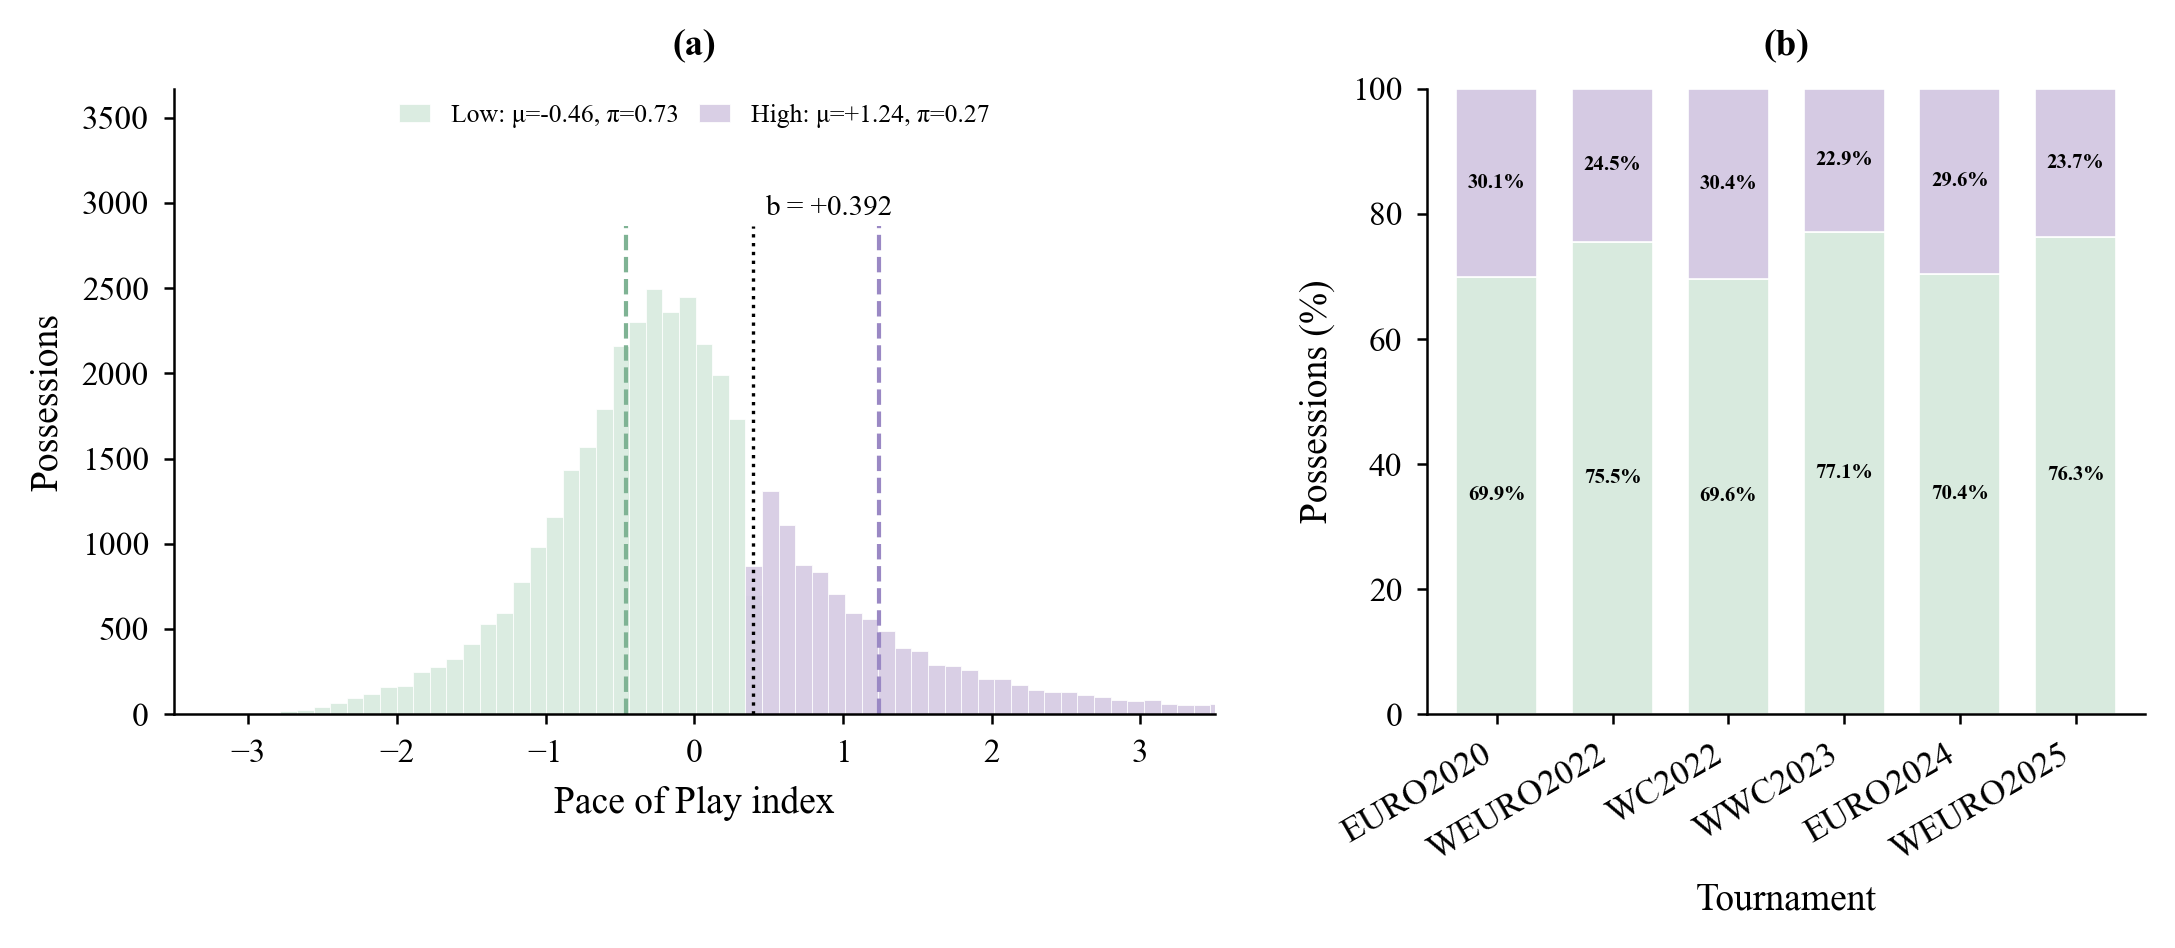

In [5]:
plt.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman"], "font.size": 9,
    "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.fontsize": 8, "axes.linewidth": 0.6, "xtick.major.width": 0.6,
    "ytick.major.width": 0.6, "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "savefig.dpi": 300, "figure.dpi": 300,
})
STATE_COLOURS = ["#d8eade", "#d5cae3"]
CENTRE_COLOURS = ["#7fb394", "#9a88c4"]
TOURN_TIMELINE = ["EURO2020", "WEURO2022", "WC2022", "WWC2023", "EURO2024", "WEURO2025"]

v, s = ppi["PPI"].to_numpy(), ppi["state"].to_numpy()
fig, ax = plt.subplots(1, 2, figsize=(7.09, 3.0), constrained_layout=True,
                       gridspec_kw={"width_ratios": [1.45, 1]})
fig.set_constrained_layout_pads(w_pad=0.02, h_pad=0.02, wspace=0.08)

a = ax[0]
bins = np.linspace(v.min(), v.max(), 80)
for k in range(K_OPT):
    a.hist(v[s == k], bins=bins, color=STATE_COLOURS[k], alpha=0.9, edgecolor="white",
           linewidth=0.2, label=f"{STATE_NAMES[k]}: μ={centres[k]:+.2f}, π={shares[k]:.2f}")
    a.axvline(centres[k], ymax=0.78, color=CENTRE_COLOURS[k], ls="--", lw=1.0)
a.set_xlim(-3.5, 3.5)
a.set_ylim(0, a.get_ylim()[1] * 1.40)
a.axvline(boundary, ymax=0.78, color="black", ls=":", lw=0.8)
a.annotate(f"b = {boundary:+.3f}", xy=(boundary, a.get_ylim()[1] * 0.81), xytext=(3, 0),
           textcoords="offset points", fontsize=7, ha="left", va="center",
           bbox=dict(facecolor="white", edgecolor="none", pad=1, alpha=0.85))
a.set_xlabel("Pace of Play index")
a.set_ylabel("Possessions")
a.legend(loc="upper center", ncol=2, fontsize=6.2, handlelength=1.2, columnspacing=0.8,
         borderaxespad=0.2)
a.set_title("(a)", fontsize=9, fontweight="bold", pad=8)

b = ax[1]
comp = (pd.crosstab(ppi["tournament"], ppi["state"], normalize="index") * 100)
comp = comp.rename(columns=STATE_NAMES).loc[TOURN_TIMELINE]
comp.plot(kind="bar", stacked=True, color=STATE_COLOURS, ax=b, width=0.7, edgecolor="white",
          linewidth=0.4, legend=False)
for c in b.containers:
    b.bar_label(c, label_type="center", fmt="%.1f%%", fontsize=5, color="black",
                fontweight="bold")
b.set_xlabel("Tournament")
b.set_ylabel("Possessions (%)")
b.set_ylim(0, 100)
b.tick_params(axis="x", rotation=30, labelsize=8.5)
for lbl in b.get_xticklabels():
    lbl.set_horizontalalignment("right")
b.set_title("(b)", fontsize=9, fontweight="bold", pad=8)

fig.savefig(f"{FIG_DIR}/Figure4_pace_states.png", dpi=300, bbox_inches="tight")
plt.show()

## 4 · Stability of the state boundary (Supplementary Figure S1)

Matches are resampled with replacement (B = 2,000) and the K = 2 boundary is re-estimated in each
replicate. For speed, each replicate uses the exact one-dimensional 2-means optimum (scan of all
contiguous splits; boundary = midpoint of the two means).

K-means boundary +0.392  (exact 2-means optimum on the full sample +0.376)
Match bootstrap (B = 2000, 292 matches): 95% CI [+0.332, +0.421], SD = 0.023
Possessions within the CI: 3.2%


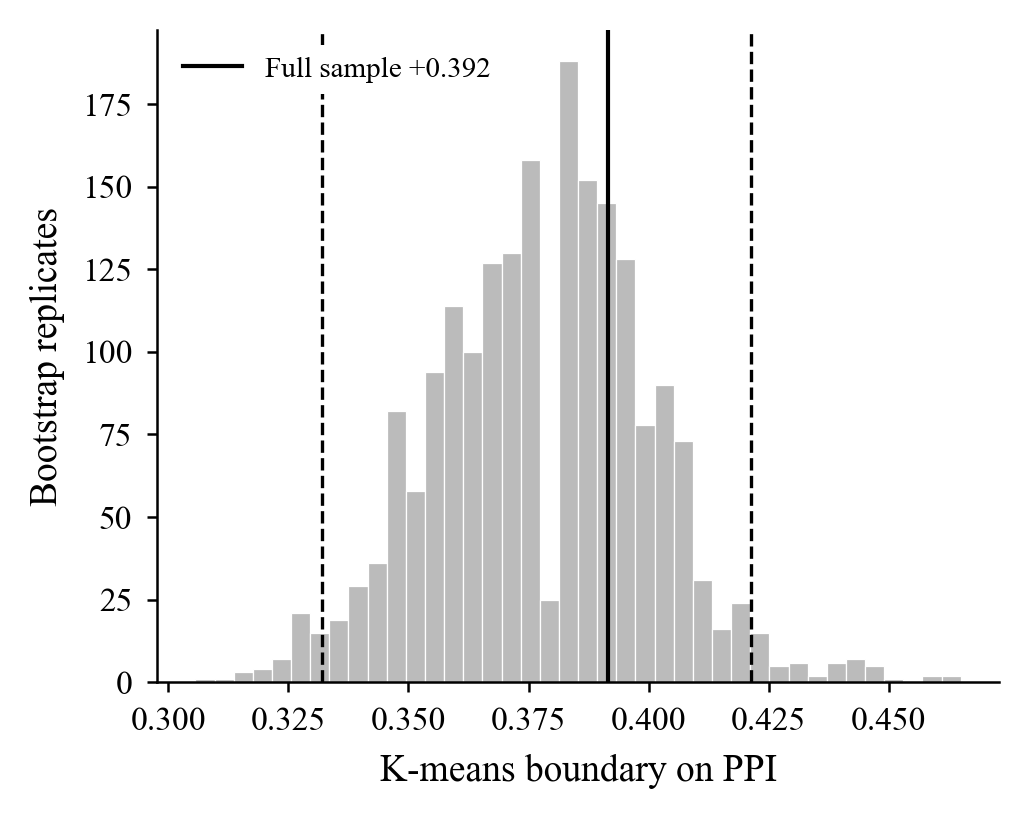

In [6]:
def two_means_boundary(x):
    xs = np.sort(np.asarray(x, dtype=float))
    n = len(xs)
    cs, cs2 = np.cumsum(xs), np.cumsum(xs ** 2)
    n_left = np.arange(1, n)
    s_l, s2_l = cs[:-1], cs2[:-1]
    s_r, s2_r = cs[-1] - s_l, cs2[-1] - s2_l
    sse = (s2_l - s_l ** 2 / n_left) + (s2_r - s_r ** 2 / (n - n_left))
    j = int(np.argmin(sse))
    return (s_l[j] / n_left[j] + s_r[j] / (n - n_left[j])) / 2


by_match = [g.to_numpy() for _, g in ppi.groupby("game_id")["PPI"]]
rng = np.random.default_rng(2025)
boot_b = np.array([two_means_boundary(np.concatenate(
    [by_match[i] for i in rng.integers(0, len(by_match), len(by_match))])) for _ in range(2000)])
b_lo, b_hi = np.quantile(boot_b, [0.025, 0.975])

print(f"K-means boundary {boundary:+.3f}  (exact 2-means optimum on the full sample "
      f"{two_means_boundary(v):+.3f})")
print(f"Match bootstrap (B = 2000, {len(by_match)} matches): 95% CI [{b_lo:+.3f}, {b_hi:+.3f}], "
      f"SD = {boot_b.std():.3f}")
print(f"Possessions within the CI: {ppi['PPI'].between(b_lo, b_hi).mean():.1%}")

fig, a = plt.subplots(figsize=(3.5, 2.8))
a.hist(boot_b, bins=40, color="#BBBBBB", edgecolor="white", linewidth=0.3)
a.axvline(boundary, color="black", lw=1.0, label=f"Full sample {boundary:+.3f}")
for q in (b_lo, b_hi):
    a.axvline(q, color="black", lw=0.8, ls="--")
a.set_xlabel("K-means boundary on PPI")
a.set_ylabel("Bootstrap replicates")
a.legend(loc="upper left", fontsize=7, frameon=True, facecolor="white", edgecolor="none",
         framealpha=1)
sns.despine(ax=a)
plt.tight_layout()
fig.savefig(f"{FIG_DIR}/FigureS1_boundary_bootstrap.png", dpi=300, bbox_inches="tight")
plt.show()

## 5 · Pace-state profile and per-feature cut-points (Table 2)

The nine PPI variables (winsorised, natural units) are summarised per state as mean ± SD, with
Cohen's d = (high − low) / pooled SD. For each variable the Youden's-J-optimal cut-point of a ROC
curve against the state assignment gives a single-variable high-pace rule, with its sensitivity,
specificity and accuracy (inter-pass interval: shorter = faster, hence "<").

In [7]:
LABELS = {
    "passes_per_minute": "Passes per minute",
    "distance_per_second": "Ball displacement per second",
    "distance_per_touch": "Ball displacement per touch",
    "time_to_pass": "Inter-pass interval",
    "spatial_compression_x": "Longitudinal spatial spread",
    "spatial_compression_y": "Lateral spatial spread",
    "goal_directed_displacement_per_second": "Goal-directed ball displacement per second",
    "progressive_action_rate": "Progressive action rate",
    "opponents_bypassed_per_second": "Opponents bypassed per second",
}
INVERT = {"time_to_pass"}
low, high = ppi[ppi["state"] == 0], ppi[ppi["state"] == 1]


def cohen_d(a, b):
    sp = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    return (b.mean() - a.mean()) / sp


rows = []
for f in ITEMS:
    score = -ppi[f].to_numpy() if f in INVERT else ppi[f].to_numpy()   # higher = faster
    fpr, tpr, thr = roc_curve(ppi["state"], score)
    j = int(np.argmax(tpr - fpr))
    rows.append({
        "Variable": LABELS[f],
        f"Low pace (n={len(low):,})": f"{low[f].mean():.3f} ± {low[f].std():.3f}",
        f"High pace (n={len(high):,})": f"{high[f].mean():.3f} ± {high[f].std():.3f}",
        "Cohen d": round(cohen_d(low[f], high[f]), 2),
        "High-pace rule": f"{'<' if f in INVERT else '>'} {(-thr[j] if f in INVERT else thr[j]):.2f}",
        "Sensitivity": round(tpr[j], 3),
        "Specificity": round(1 - fpr[j], 3),
        "Accuracy": round(((score >= thr[j]).astype(int) == ppi["state"]).mean(), 3),
    })
table_2 = pd.DataFrame(rows)
print(table_2.to_string(index=False))
table_2.to_csv(f"{FIG_DIR}/Table2_pace_state_profile.csv", index=False)

                                  Variable Low pace (n=29,164) High pace (n=10,831)  Cohen d High-pace rule  Sensitivity  Specificity  Accuracy
                         Passes per minute      17.489 ± 5.985       25.296 ± 8.629     1.15        > 21.11        0.648        0.783     0.747
              Ball displacement per second       7.481 ± 1.973        9.524 ± 2.513     0.96         > 8.14        0.686        0.705     0.700
               Ball displacement per touch      12.159 ± 5.377       12.753 ± 6.223     0.11        > 14.97        0.261        0.804     0.657
                       Inter-pass interval       3.955 ± 1.496        2.845 ± 1.239    -0.78         < 2.97        0.637        0.750     0.719
               Longitudinal spatial spread       7.714 ± 1.619        8.008 ± 1.747     0.18         > 8.59        0.360        0.721     0.623
                    Lateral spatial spread      13.116 ± 2.780       12.896 ± 3.091    -0.08        > 16.42        0.147        0.879   

## 6 · Save pace states

In [8]:
ppi[["game_id", "possession", "possession_team_id", "tournament", "sex", "PPI", "state"]].to_hdf(
    PPI_H5, key="pace_states", mode="a", complevel=5)
print(f"Saved pace_states → {PPI_H5}")

Saved pace_states → ../data/ppi-features.h5
